# TP4 : Architecture Transformer

## 1. Génération du dataset
Série temporelle `s = sin(x)` : 200 valeurs entre 0 et 20, rangées en séquences de dimension 10. Chaque séquence `X` prédit la valeur suivante `Y`.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 200 valeurs de sin(x) entre 0 et 20
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

# Séquences de dimension 10 : X = [s0..s9], [s1..s10], ... ; Y = [s10], [s11], ...
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue par les modèles : (nombre de séquences, longueur, 1)
X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Découpage chronologique : début pour apprendre, fin pour tester
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X :", X.shape)
print("y :", y.shape)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Premier exemple X :", X[0].squeeze().tolist())
print("Premier exemple Y :", y[0].item())

X : torch.Size([190, 10, 1])
y : torch.Size([190, 1])
X_train : torch.Size([150, 10, 1]) | X_test : torch.Size([40, 10, 1])
Premier exemple X : [0.0, 0.10033340752124786, 0.199654221534729, 0.29696008563041687, 0.39126893877983093, 0.48162901401519775, 0.5671283602714539, 0.6469041109085083, 0.7201511263847351, 0.7861301898956299]
Premier exemple Y : 0.8441754579544067


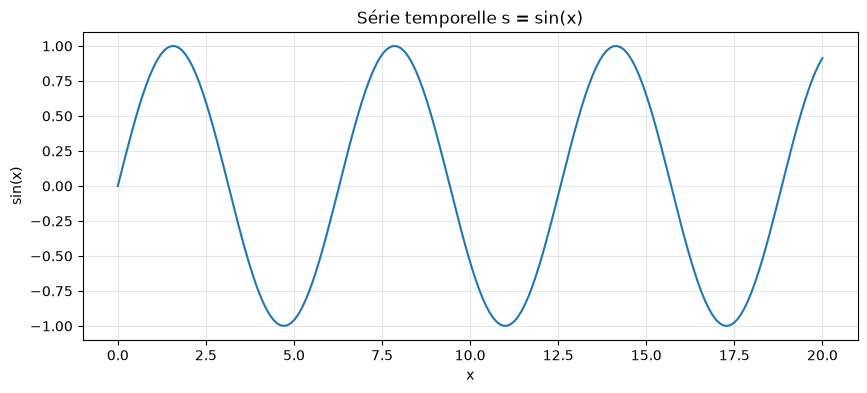

In [2]:
plt.figure(figsize=(10, 4))
plt.plot(periode, serie)
plt.title("Série temporelle s = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.show()

## 2. Modèle RNN
Architecture : RNN (16 unités) qui lit la séquence de 10 valeurs, puis une couche Linear 16 → 1 appliquée au dernier état caché pour prédire la valeur suivante.

In [4]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)          # (batch, 10, 16)
        dernier_etat = etats[:, -1, :]  # (batch, 16)
        return self.sortie(dernier_etat)  # (batch, 1)


modele_rnn = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)

print(modele_rnn)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)


In [6]:
# Entraînement
modele_rnn.train()
for epoch in range(300):
    predictions = modele_rnn(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# Test
modele_rnn.eval()
with torch.no_grad():
    predictions_rnn = modele_rnn(X_test)
    erreur_test_rnn = critere(predictions_rnn, y_test)

print(f"\nErreur de test : {erreur_test_rnn.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions_rnn[0].item():.4f}")

Epoch  50 | Erreur : 0.000013
Epoch 100 | Erreur : 0.000012
Epoch 150 | Erreur : 0.000011
Epoch 200 | Erreur : 0.000010
Epoch 250 | Erreur : 0.000009
Epoch 300 | Erreur : 0.000008

Erreur de test : 0.000010
Valeur réelle  : -0.3639
Valeur prédite : -0.3636


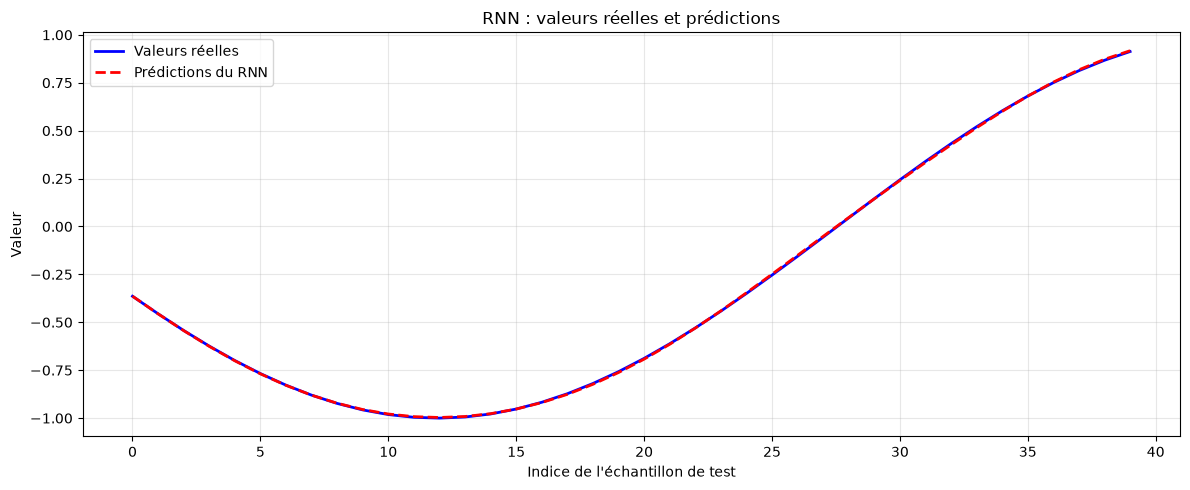

In [7]:
valeurs_reelles = y_test.detach().numpy().reshape(-1)
valeurs_predites = predictions_rnn.detach().numpy().reshape(-1)

plt.figure(figsize=(12, 5))
plt.plot(valeurs_reelles, label="Valeurs réelles", color="blue", linewidth=2)
plt.plot(valeurs_predites, label="Prédictions du RNN", color="red", linestyle="--", linewidth=2)
plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()